In [1]:
# --- Setup: make the project root importable ---
import sys
from pathlib import Path

# The notebook runs from notebooks/, so the project root is one level up
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw, add_target
from src.config import TARGET_COL, FIGURES_DIR

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)  # make sure the folder exists

df = add_target(load_raw("por"))
print("Shape:", df.shape)
df.head()

Shape: (649, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,fail
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,0


In [2]:
# --- Class imbalance: counts and percentages ---
counts = df[TARGET_COL].value_counts().sort_index()          # 0 = pass, 1 = fail
pct = df[TARGET_COL].value_counts(normalize=True).sort_index() * 100

print(f"Pass (0): {counts[0]} students ({pct[0]:.1f}%)")
print(f"Fail (1): {counts[1]} students ({pct[1]:.1f}%)")

# A "dumb" model that always predicts the majority class (Pass)
baseline_acc = pct.max()
print(f"\nAlways-predict-Pass accuracy: {baseline_acc:.1f}%")
print("→ Any model must clearly beat this, and accuracy alone can't show it.")

Pass (0): 549 students (84.6%)
Fail (1): 100 students (15.4%)

Always-predict-Pass accuracy: 84.6%
→ Any model must clearly beat this, and accuracy alone can't show it.


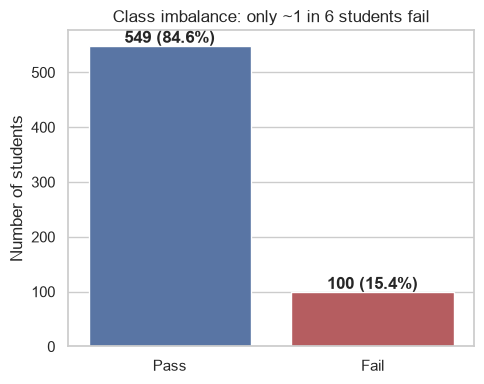

In [3]:
# --- Bar chart of the class balance ---
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Pass", "Fail"], y=counts.values, ax=ax,
            hue=["Pass", "Fail"], palette=["#4C72B0", "#C44E52"], legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")

ax.set_title("Class imbalance: only ~1 in 6 students fail")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_imbalance.png", dpi=150)
plt.show()

In [4]:
from src.config import GRADE_COLS

# All input features = everything except grades and the target
feature_cols = [c for c in df.columns if c not in GRADE_COLS + [TARGET_COL]]

num_cols = df[feature_cols].select_dtypes(include="number").columns.tolist()
cat_cols = df[feature_cols].select_dtypes(exclude="number").columns.tolist()

print(f"Features: {len(feature_cols)}  |  numeric: {len(num_cols)}  |  categorical: {len(cat_cols)}")
print("Numeric:    ", num_cols)
print("Categorical:", cat_cols)

Features: 30  |  numeric: 13  |  categorical: 17
Numeric:     ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


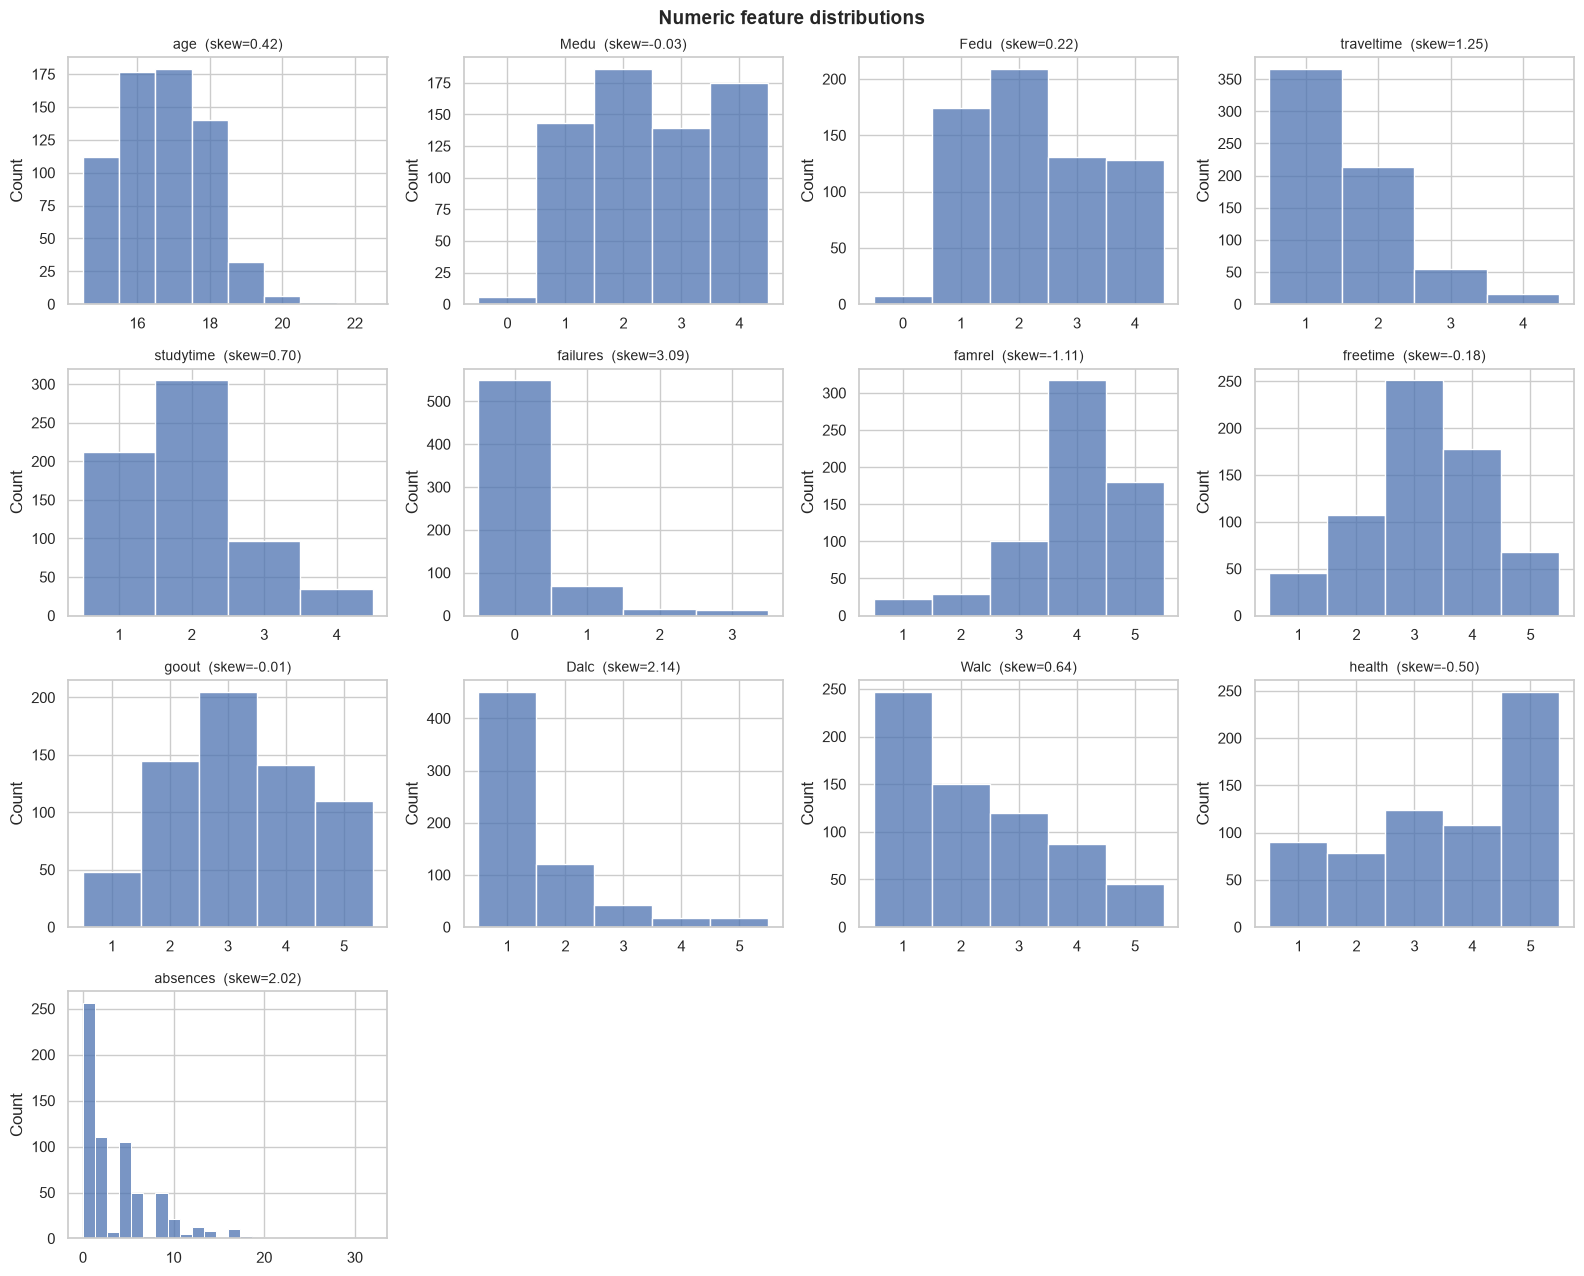

In [5]:
# One histogram per numeric feature, with skewness in the title
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.ravel()  # flatten the 4x4 grid into a simple list

for ax, col in zip(axes, num_cols):
    # discrete=True draws one bar per value for small integer scales
    sns.histplot(df[col], ax=ax, discrete=df[col].nunique() <= 10, color="#4C72B0")
    ax.set_title(f"{col}  (skew={df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(num_cols):]:   # hide the unused empty subplots
    ax.set_visible(False)

fig.suptitle("Numeric feature distributions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_numeric_distributions.png", dpi=150)
plt.show()

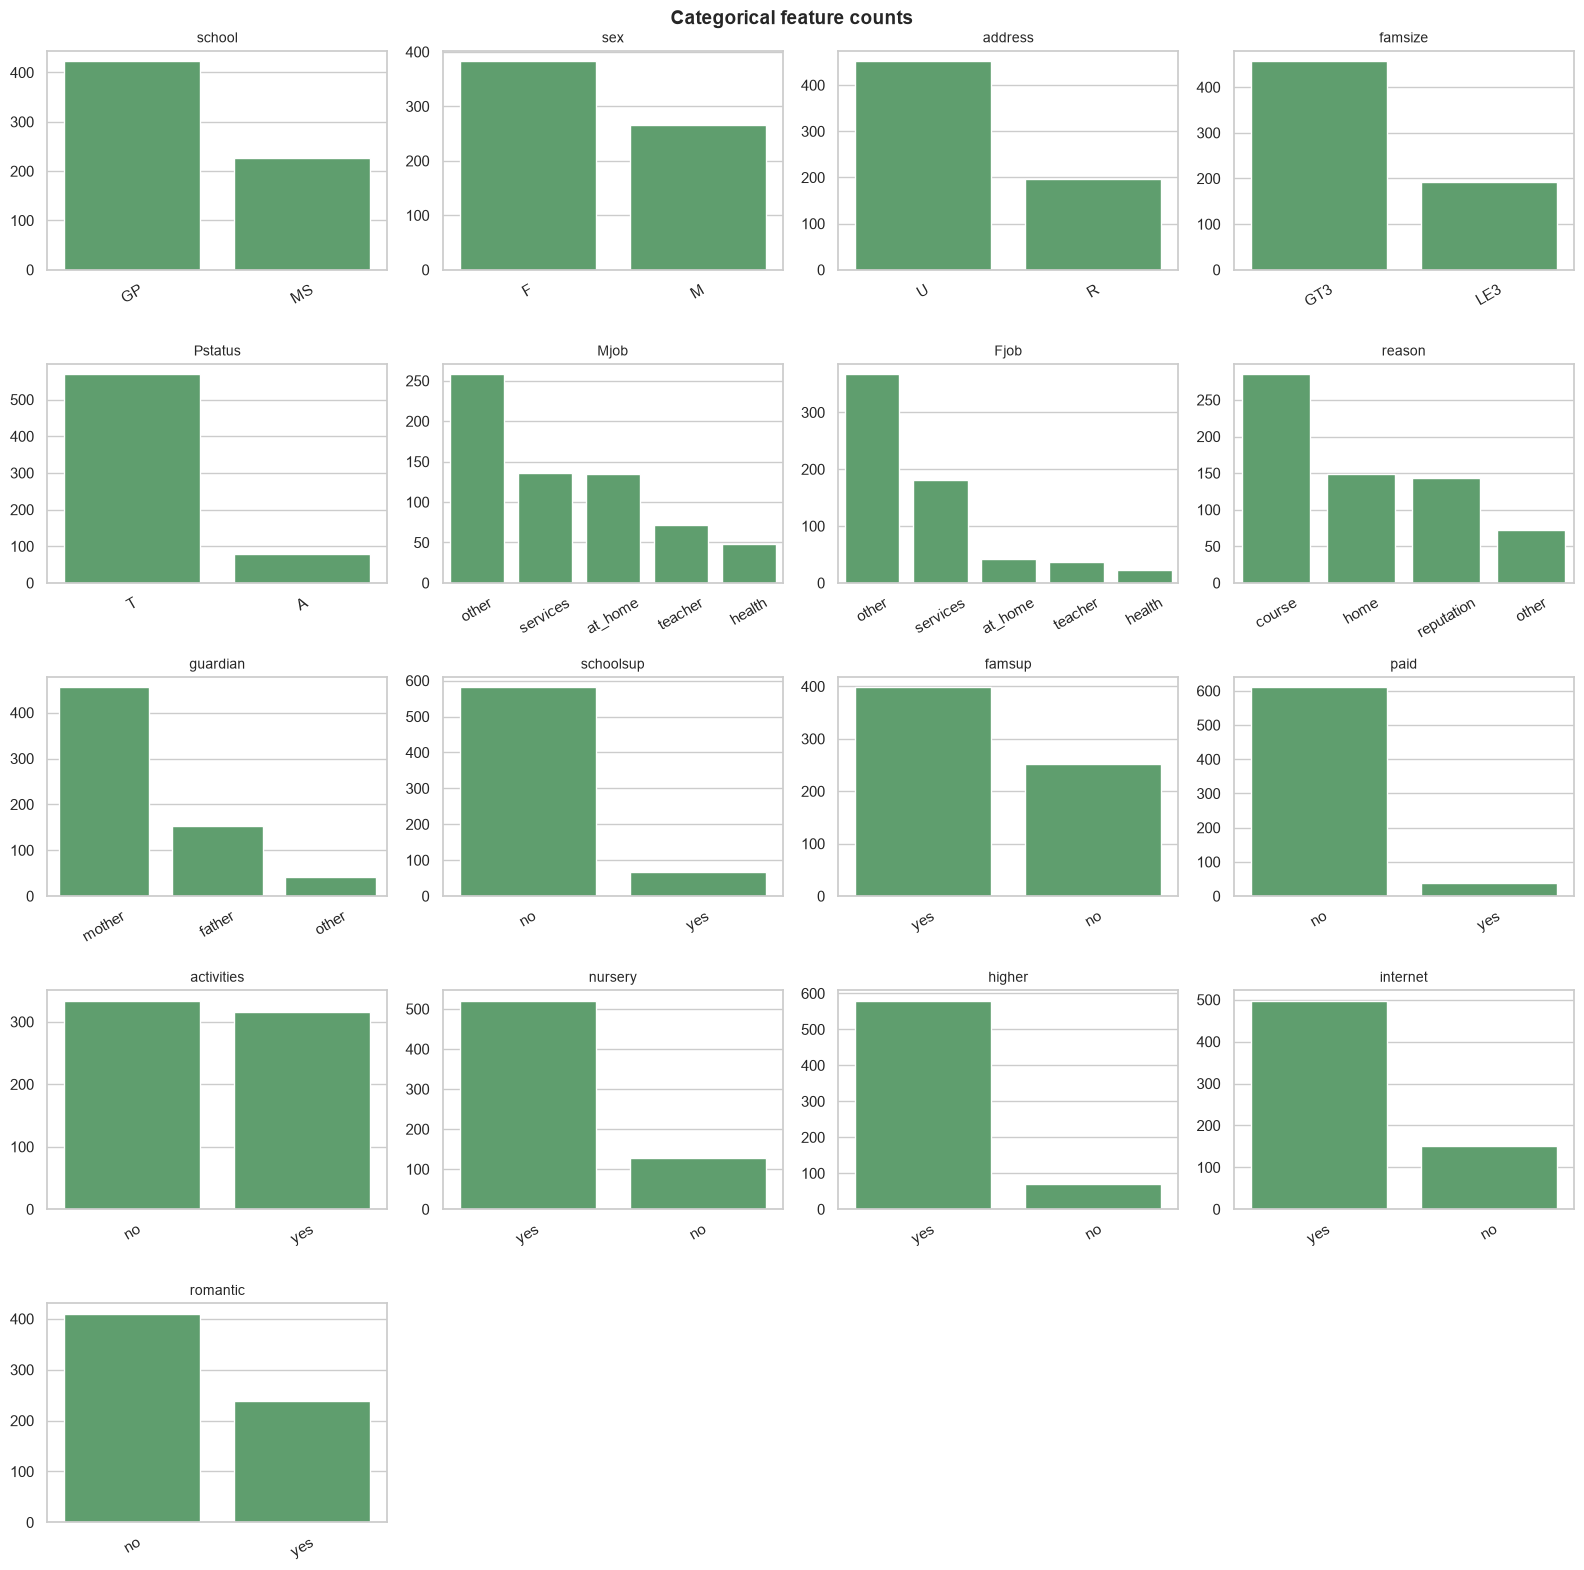

In [6]:
# One bar chart per categorical feature, most common value first
n = len(cat_cols)
ncols = 4
nrows = -(-n // ncols)  # ceiling division: enough rows for all charts

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(x=col, data=df, order=order, ax=ax, color="#55A868")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("Categorical feature counts", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_categorical_counts.png", dpi=150)
plt.show()

In [7]:
# 1) Students with a final grade of exactly 0
zero_g3 = df[df["G3"] == 0]
print(f"Students with G3 = 0: {len(zero_g3)} ({len(zero_g3) / len(df):.1%} of all)")
print("Their average G1 and G2:", zero_g3[["G1", "G2"]].mean().round(1).to_dict())

# 2) Absences: the typical student vs the extreme
print(f"\nAbsences: median = {df['absences'].median():.0f}, "
      f"mean = {df['absences'].mean():.1f}, max = {df['absences'].max()}")

Students with G3 = 0: 15 (2.3% of all)
Their average G1 and G2: {'G1': 7.1, 'G2': 3.8}

Absences: median = 2, mean = 3.7, max = 32


            corr_with_fail  corr_with_G3
failures             0.380        -0.393
studytime           -0.165         0.250
Fedu                -0.146         0.212
Medu                -0.145         0.240
Dalc                 0.124        -0.205
Walc                 0.116        -0.177
age                  0.111        -0.107
freetime             0.093        -0.123
absences             0.087        -0.091
goout                0.067        -0.088
traveltime           0.058        -0.127
famrel              -0.045         0.063
health               0.010        -0.099


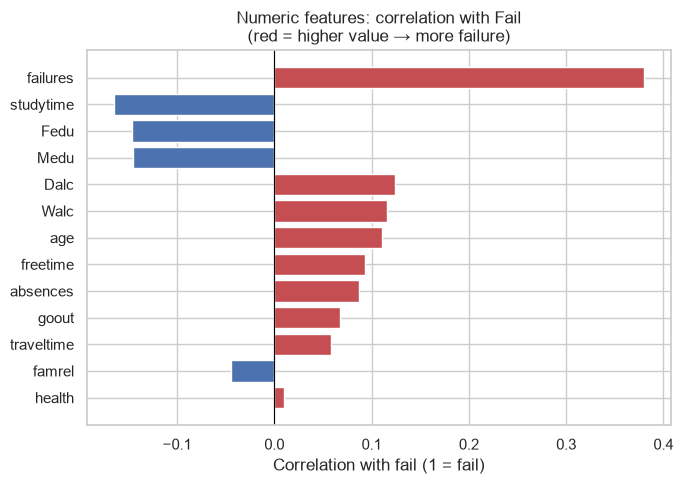

In [8]:
# Correlation of each numeric feature with fail (1 = fail) and with G3
corr = pd.DataFrame({
    "corr_with_fail": df[num_cols].corrwith(df[TARGET_COL]),
    "corr_with_G3":   df[num_cols].corrwith(df["G3"]),
}).sort_values("corr_with_fail", key=abs, ascending=False)  # strongest first, ignoring sign

print(corr.round(3))

# Bar chart: red = higher value -> more failure, blue = higher value -> less failure
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in corr["corr_with_fail"]]
ax.barh(corr.index, corr["corr_with_fail"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()  # strongest at the top
ax.set_title("Numeric features: correlation with Fail\n(red = higher value → more failure)")
ax.set_xlabel("Correlation with fail (1 = fail)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_numeric_corr_with_fail.png", dpi=150)
plt.show()

In [9]:
overall = df[TARGET_COL].mean()   # overall fail rate, about 15%
rows = []
for col in cat_cols:
    rates = df.groupby(col)[TARGET_COL].mean()   # fail rate for each category
    rows.append({
        "feature": col,
        "lowest_fail_rate":  rates.min(),
        "highest_fail_rate": rates.max(),
        "spread": rates.max() - rates.min(),      # how different the groups are
        "worst_group": rates.idxmax(),            # category with the highest fail rate
    })

cat_summary = pd.DataFrame(rows).sort_values("spread", ascending=False).set_index("feature")
print(f"Overall fail rate: {overall:.1%}\n")
cat_summary.round(3)

Overall fail rate: 15.4%



,lowest_fail_rate,highest_fail_rate,spread,worst_group
feature,,,,
higher,0.116,0.478,0.363,no
school,0.076,0.301,0.225,MS
reason,0.070,0.250,0.180,other
Mjob,0.056,0.215,0.159,at_home
guardian,0.105,0.220,0.115,other
address,0.124,0.223,0.099,R
Fjob,0.083,0.182,0.099,services
paid,0.149,0.231,0.082,yes
internet,0.137,0.212,0.075,no


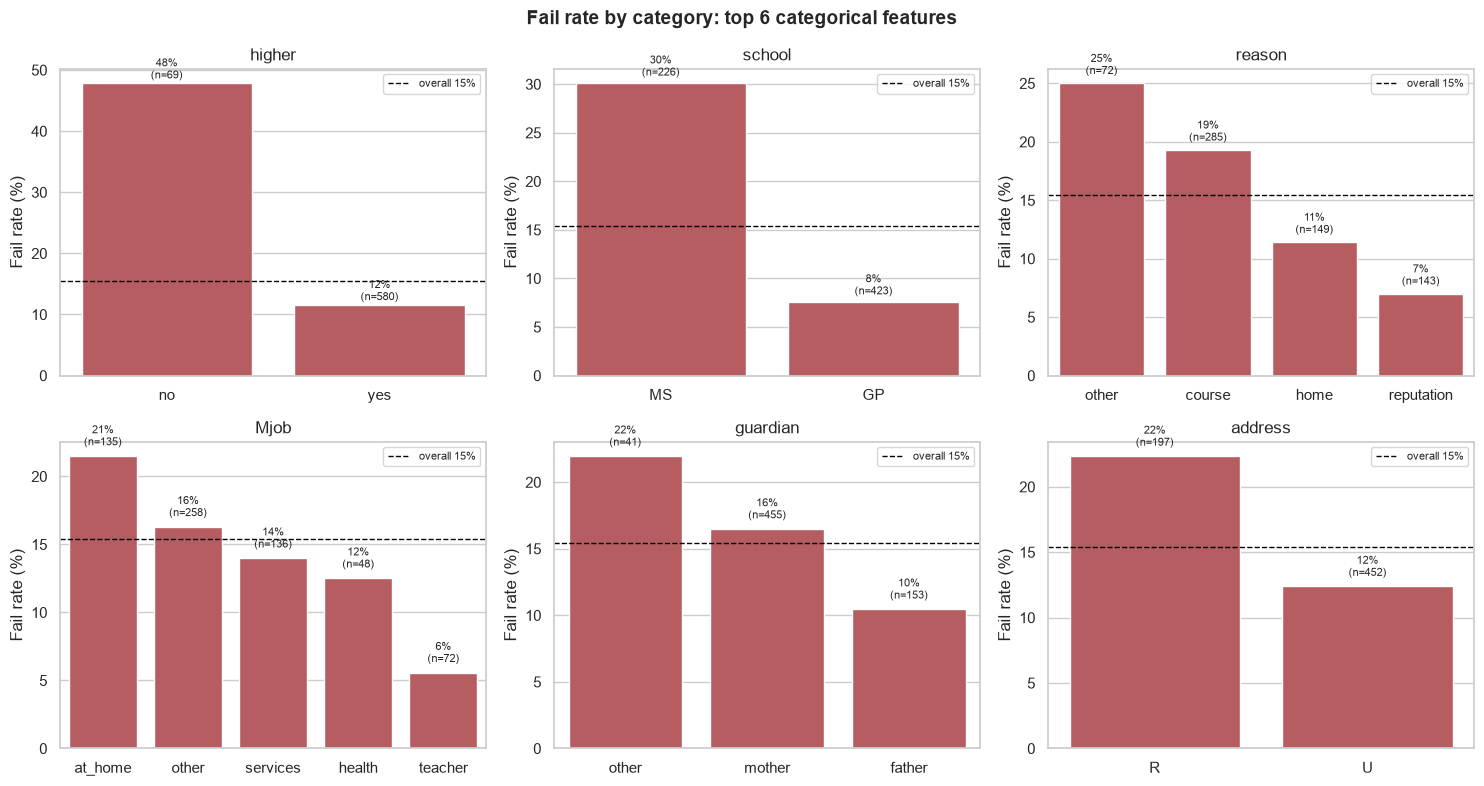

In [10]:
top_cats = cat_summary.index[:6].tolist()   # the 6 features with the biggest spread

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col in zip(axes, top_cats):
    rates = df.groupby(col)[TARGET_COL].mean().sort_values(ascending=False) * 100
    n = df[col].value_counts()   # group sizes, to judge how reliable each bar is
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color="#C44E52")
    ax.axhline(overall * 100, color="black", linestyle="--", linewidth=1,
               label=f"overall {overall:.0%}")
    for i, (cat, v) in enumerate(rates.items()):
        ax.text(i, v + 0.8, f"{v:.0f}%\n(n={n[cat]})", ha="center", fontsize=8)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("Fail rate (%)")
    ax.legend(fontsize=8)

fig.suptitle("Fail rate by category: top 6 categorical features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_fail_rate_by_category.png", dpi=150)
plt.show()

In [11]:
fr = df.groupby("failures")[TARGET_COL].agg(fail_rate="mean", students="count")
fr["fail_rate"] = (fr["fail_rate"] * 100).round(1)
fr

,fail_rate,students
failures,,
0,9.3,549
1,45.7,70
2,50.0,16
3,64.3,14


         G1     G2     G3   fail
G1    1.000  0.865  0.826 -0.563
G2    0.865  1.000  0.919 -0.592
G3    0.826  0.919  1.000 -0.663
fail -0.563 -0.592 -0.663  1.000


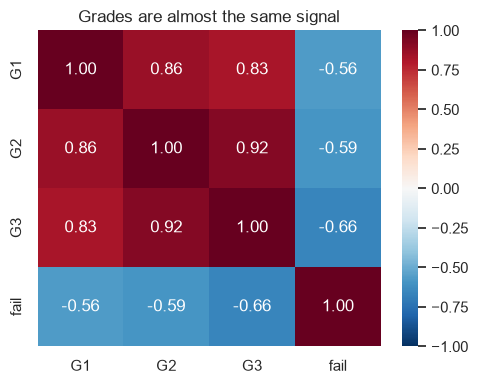

In [12]:
from src.config import PASS_THRESHOLD

# Correlation between the three grades and the fail target
grade_corr = df[["G1", "G2", "G3", TARGET_COL]].corr()
print(grade_corr.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(grade_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Grades are almost the same signal")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_grade_correlations.png", dpi=150)
plt.show()

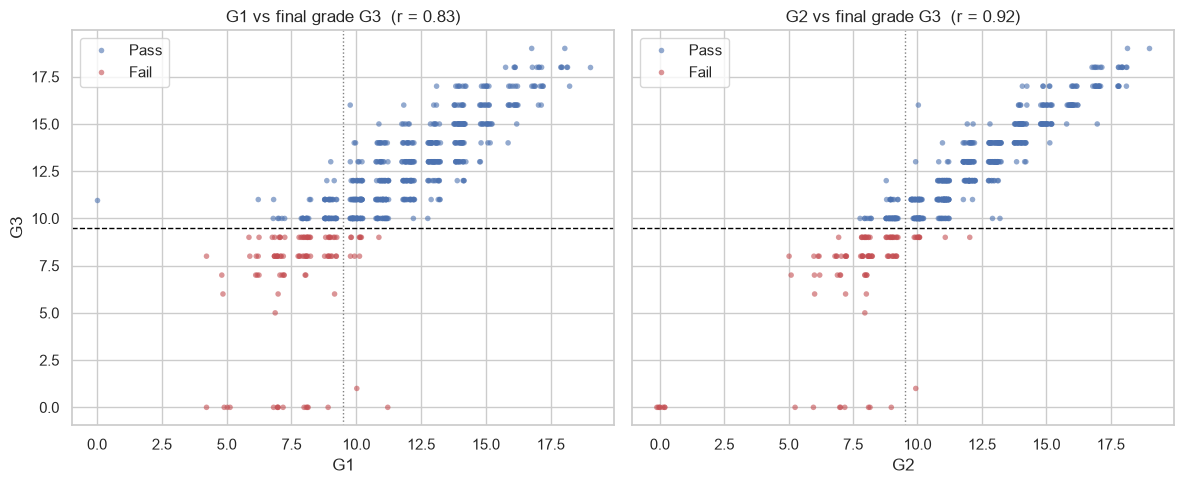

In [13]:
# Each dot = one student, coloured by whether they failed
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, g in zip(axes, ["G1", "G2"]):
    sns.stripplot(x=g, y="G3", data=df, ax=ax,
                  hue=df[TARGET_COL].map({0: "Pass", 1: "Fail"}),
                  palette={"Pass": "#4C72B0", "Fail": "#C44E52"},
                  jitter=0.25, alpha=0.6, size=4, native_scale=True)
    ax.axhline(PASS_THRESHOLD - 0.5, color="black", linestyle="--", linewidth=1)  # pass line on G3
    ax.axvline(PASS_THRESHOLD - 0.5, color="gray", linestyle=":", linewidth=1)    # pass line on G1/G2
    ax.set_title(f"{g} vs final grade G3  (r = {df[g].corr(df['G3']):.2f})")
    ax.legend(title="")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_grades_vs_G3.png", dpi=150)
plt.show()

In [14]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

y = df[TARGET_COL]
rules = {
    "Always predict Pass (baseline)": pd.Series(0, index=df.index),
    "Rule: G1 < 10 → Fail": (df["G1"] < PASS_THRESHOLD).astype(int),
    "Rule: G2 < 10 → Fail": (df["G2"] < PASS_THRESHOLD).astype(int),
}

results = pd.DataFrame({
    name: {
        "accuracy":       accuracy_score(y, pred),
        "fail_recall":    recall_score(y, pred, zero_division=0),
        "fail_precision": precision_score(y, pred, zero_division=0),
    }
    for name, pred in rules.items()
}).T

(results * 100).round(1)

,accuracy,fail_recall,fail_precision
Always predict Pass (baseline),84.6,0.0,0.0
Rule: G1 < 10 → Fail,87.5,88.0,56.1
Rule: G2 < 10 → Fail,89.7,89.0,61.4
